# Lofting sections

A loft builds a solid through planar sections. Every section is a planex2d face on its own plane in 3D, and
`occ.ThruSections` lofts their outlines. The example is a wing half with NACA 2412 sections. It tapers from a chord of
100 to 50 over 300, with 3° dihedral and 3° washout, and then bends with a radius of 20 into a winglet canted at 75°,
60 long, swept back by 30° and tapered to a chord of 25.

When the sections change quickly, a loft between them can overshoot. See [lofts with guide curves](guided-loft.md)
for how to steer it.

In [1]:
import math
import matplotlib.pyplot as plt
import netgen.occ as occ
from ngsolve_webgpu.jupyter import Draw
import planex as px

In [2]:
from docs_figures import Row, Vertices

The numbers of the wing: the root chord `c_root` tapers to `c_tip` over the span `b`, with `washout` and `dihedral` in
degrees. The bend has the radius `R` and turns up to the winglet's `cant`, and the winglet is `hw` long, with the tip
chord `c_winglet` and the `sweep` angle.

In [3]:
c_root, c_tip, b, washout, dihedral = 100, 50, 300, 3, 3
R, cant, hw, c_winglet, sweep = 20, 75, 60, 25, 30

## The profile

`px.FromNACA` returns the airfoil as a face, here with 2 % camber at 40 % of the chord, 12 % thickness and a sharp
trailing edge. The leading edge sits at the origin of its plane, with the chord along h, and `angle` turns the profile
nose up about the quarter chord point (`pivot`).

In [4]:
root = px.FromNACA("2412", chord=c_root)

In [5]:
Row((root, "NACA 2412, chord 100"))

The plane of each section is perpendicular to the span line, with its origin a quarter chord ahead of it, so the
quarter chord points lie on the span line and the twist turns about them. The cambered upper side points away from
the bend, so on the winglet it faces inboard. Washout lowers the nose, which is a negative angle.

In [6]:
def section(q, phi, c, twist):
    f = math.radians(phi)
    plane = px.Plane(origin=(q[0] - c / 4, q[1], q[2]), normal=(0, -math.cos(f), -math.sin(f)), axis=(1, 0, 0))
    return px.FromNACA("2412", chord=c, angle=-twist, plane=plane)

## Along the span

The span line rises at the dihedral angle, bends with radius R up to the cant angle and continues straight into the
winglet, and s is the distance along it. The loft interpolates smoothly between the sections, so they are placed
evenly along the span line, about every 10.

In [7]:
g, k = math.radians(dihedral), math.radians(cant)
bend = R * (k - g)
center = (0, b * math.cos(g) - R * math.sin(g), b * math.sin(g) + R * math.cos(g))

def station(s):
    if s <= b:
        return section((0, s * math.cos(g), s * math.sin(g)), dihedral, c_root + (c_tip - c_root) * s / b,
                       washout * s / b)
    if s <= b + bend:
        f = g + (s - b) / R
        return section((0, center[1] + R * math.sin(f), center[2] - R * math.cos(f)), math.degrees(f), c_tip,
                       washout)
    h = s - b - bend
    y0, z0 = center[1] + R * math.sin(k), center[2] - R * math.cos(k)
    return section((h * math.tan(math.radians(sweep)), y0 + h * math.cos(k), z0 + h * math.sin(k)), cant,
                   c_tip + (c_winglet - c_tip) * h / hw, washout)

length = b + bend + hw
count = round(length / 10)
sections = [station(length * i / count) for i in range(count + 1)]
px.Plot3d(sections)

## The loft

In [8]:
wing = occ.ThruSections([s.outer.ToOCCWire() for s in sections], solid=True)
px.Plot3d(wing)

The wing is shown from the front and from above, with the sections in black and the edges of the loft in red.

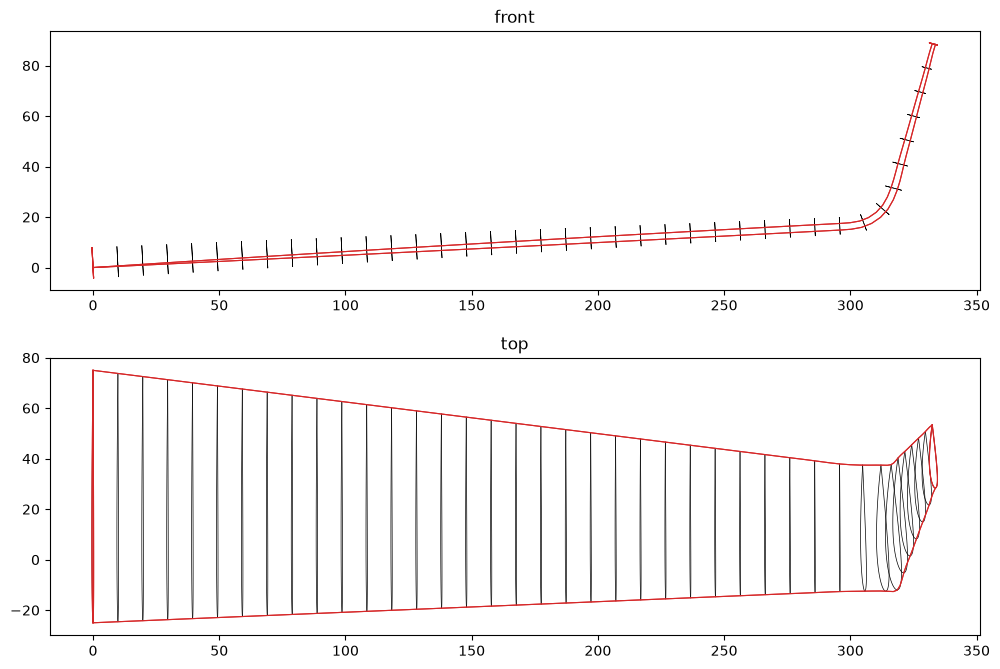

In [9]:
def views(axes, edges, **style):
    for e in edges:
        t0, t1 = e.parameter_interval
        pts = [e.Value(t0 + (t1 - t0) * j / 100) for j in range(101)]
        axes[0].plot([q.y for q in pts], [q.z for q in pts], **style)
        axes[1].plot([q.y for q in pts], [q.x for q in pts], **style)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
views(axes, [e for s in sections for e in s.outer.ToOCCWire().edges], color="black", lw=0.5)
views(axes, wing.edges, color="tab:red", lw=0.8)
for ax, title in zip(axes, ("front", "top")):
    ax.set_aspect("equal")
    ax.set_title(title)
plt.show()

Both halves, with the second one mirrored about the plane of symmetry:

In [10]:
px.Plot3d([wing, wing.Mirror(occ.Axes((0, 0, 0), n=occ.Y, h=occ.X))])

## Check

The end caps of the solid are the root and tip sections, with the same area and the same centroid.

In [11]:
for name, cap, s in (("root", wing.faces.Min(occ.Y), sections[0]), ("tip", wing.faces.Max(occ.Z), sections[-1])):
    f = s.ToOCCFace()
    print(name, "cap", cap.mass, "section", f.mass, "centroids", (cap.center - f.center).Norm(), "apart")

root cap 817.7744876597249 section 817.7744876597251 centroids 4.080187622190639e-15 apart
tip cap 51.110905478732974 section 51.110905478732704 centroids 1.154495294690031e-13 apart


The straight parts are frusta of similar sections. The bend is the tip section turned about the bend axis, so by
Pappus's theorem its volume is the area times the path of the section's centroid, which camber and washout move
slightly off the radius R. The smooth loft rounds the corners where the parts meet, so the sum agrees closely but not
exactly:

In [12]:
unit = sections[0].ToOCCFace().mass / c_root**2

def frustum(c1, c2, L):
    return unit * L * (c1**2 + c1 * c2 + c2**2) / 3

centroid = station(b + bend / 2).ToOCCFace().center
arm = math.hypot(centroid.y - center[1], centroid.z - center[2])
parts = frustum(c_root, c_tip, b) + unit * c_tip**2 * arm * (k - g) + frustum(c_tip, c_winglet, hw)
print("centroid", arm, "from the bend axis, R =", R)
print("volume", wing.mass, "parts", parts, "relative difference", (wing.mass - parts) / parts)

centroid 18.78062133328242 from the bend axis, R = 20
volume 155091.44574105335 parts 155091.01843317546 relative difference 2.755207117796072e-06


In [13]:
from netgen.webgui import Draw as WebguiDraw
import sys
sys.path.insert(0, "../..")
from gallery import save_scene, save_figure, HIDDEN
both = occ.Compound([wing, wing.Mirror(occ.Axes((0, 0, 0), n=occ.Y, h=occ.X))])
both.faces.col = (0.16, 0.38, 0.72)
save_scene(WebguiDraw(both, euler_angles=[-42.22079907043641, 17.604485750278798, 52.28645547692115], settings=HIDDEN, show=False), "wing")